In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
VARIANT = "den" #den or raw for denoised or raw data
#DIAG_XLSX = "data/Diagnostics.xlsx"
#KEEP_MASK = "keep_mask.npy"
DIAG_XLSX= "/content/drive/MyDrive/PWDL/Diagnostics.xlsx"
KEEP_MASK= "/content/drive/MyDrive/PWDL/keep_mask.npy"
X_PATH = f"/content/drive/MyDrive/PWDL/X_{VARIANT}.npy"
NL, T = 12, 5000 #number of leads, number of samples per lead

In [4]:
diag = pd.read_excel(DIAG_XLSX)
keep = np.load(KEEP_MASK)
Xmm = np.load(X_PATH, mmap_mode="r")
assert Xmm.shape == (len(diag), T, NL) and len(keep) == len(diag)
print(Xmm.shape, keep.sum(), "files kept after QC")

(10646, 5000, 12) 10587 files kept after QC


In [5]:
#merge rythms as in the paper, keeping only AFIB, SB, SR, ST

merge ={
    "AFIB": "AFIB",
    "SB": "SB",
    "SR": "SR",
    "ST": "ST",
}
print(diag["Rhythm"].value_counts())
print("codes dropped by the filter:" , set(diag["Rhythm"].dropna().unique()) - set(merge))

diag["RhythmGroup"]= diag["Rhythm"].map(merge)
keep_task = keep & diag["RhythmGroup"].notna().to_numpy()

classes = sorted(diag.loc[keep_task, "RhythmGroup"].unique())
class_to_id = {c:i for i,c in enumerate(classes)}
y_rhythm = diag["RhythmGroup"].map(class_to_id).fillna(-1).astype(np.int64).to_numpy()

Rhythm
SB       3889
SR       1826
AFIB     1780
ST       1568
SVT       587
AF        445
SA        399
AT        121
AVNRT      16
AVRT        8
SAAWR       7
Name: count, dtype: int64
codes dropped by the filter: {'SA', 'AF', 'AVRT', 'AT', 'AVNRT', 'SVT', 'SAAWR'}


Text(0.5, 1.0, 'Rhythm distribution after merge')

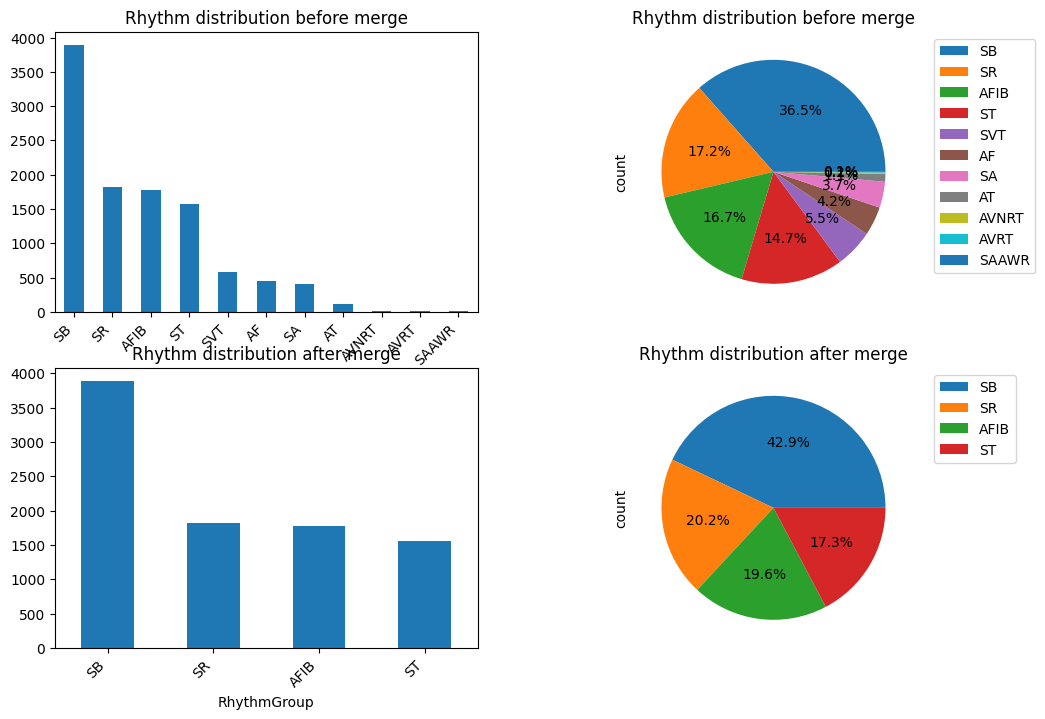

In [6]:
# 2x2 plot, top row before merge, bottom row after merge, left column bar plot, right column pie chart
#plot the class distribution of the rhythms in the dataset before the merge
#and below the class distribution after the merge, with class labels on the x axis

plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1)
diag["Rhythm"].value_counts().plot(kind="bar")
plt.xticks(rotation=45, ha="right")
plt.title("Rhythm distribution before merge")
plt.subplot(2, 2, 2)
#labels as a legend on the right side of the pie chart, no labels on the pie chart itself
diag["Rhythm"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    labels=None
)
plt.legend(labels=diag["Rhythm"].value_counts().index, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.title("Rhythm distribution before merge")
plt.subplot(2, 2, 3)
diag.loc[keep_task, "RhythmGroup"].value_counts().plot(kind="bar")
plt.xticks(rotation=45, ha="right")
plt.title("Rhythm distribution after merge")
plt.subplot(2, 2, 4)
diag.loc[keep_task, "RhythmGroup"].value_counts().plot(kind="pie", autopct='%1.1f%%', labels=None)
plt.legend(labels=diag.loc[keep_task, "RhythmGroup"].value_counts().index, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.title("Rhythm distribution after merge")



In [7]:
from sklearn.model_selection import train_test_split

In [8]:
print(len(diag), len(keep), len(keep_task), len(y_rhythm), Xmm.shape[0])

10646 10646 10646 10646 10646


In [9]:
idx = np.flatnonzero(keep_task)
train_idx, tmp_idx = train_test_split(idx, test_size=0.3, random_state=42, stratify=y_rhythm[idx])
val_idx, test_idx = train_test_split(tmp_idx, test_size=0.5, random_state=42, stratify=y_rhythm[tmp_idx])
print("train:", len(train_idx), "val:", len(val_idx), "test:", len(test_idx))

train: 6339 val: 1358 test: 1359


In [10]:
#per lead normalization
s1 = np.zeros(NL)
s2 = np.zeros(NL)
n = 0
for i in train_idx:
    s = np.asarray(Xmm[i], dtype=np.float64)
    s1 += s.sum(axis=0)
    s2 += (s**2).sum(axis=0)
    n += s.shape[0]
mean = s1/n
std = np.sqrt(s2/n - mean**2) + 1e-8
mean, std = mean.astype(np.float32), std.astype(np.float32)

In [11]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers as L
from tensorflow.keras import regularizers as re
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report

In [12]:
labels = y_rhythm

def make_ds(indices, batch=64, training=False):
    indices = np.asarray(indices)
    def gen():
        order = np.random.permutation(indices) if training else indices
        for i in order:
            yield (np.asarray(Xmm[i]) - mean) / std, labels[i]
    ds = tf.data.Dataset.from_generator(
        gen, output_signature=(tf.TensorSpec((T, NL), tf.float32),
                               tf.TensorSpec(labels.shape[1:], labels.dtype)))
    return ds.batch(batch).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(train_idx, training=True)
val_ds = make_ds(val_idx)
test_ds = make_ds(test_idx)

In [13]:
class FFTLayer(L.Layer):
  # initial convolutional block consisting of two Conv1D layers, each with 32 filters
  # to automatically extract local spatial features from the raw ECG signal to produce the
  # feature map.
  # After each Conv1D layer, a Fast Fourier Transform (FFT) layer is used to extract
  # features in the frequency domain, enabling the network to learn important frequency-
  # based features.
  # At the end of the convolutional block, a MaxPooling1D layer is added to reduce data
  # dimensionality

  """
  Applies the FFT along the time axis and returns the magnitude spectrum.
  The input has shape (batch, time, channels)
  The output maintains the same shape
  """

  def call(self, x):
    x = tf.cast(x, tf.float32)
    x = tf.transpose(x, perm=[0, 2, 1]) #time has to be the last dimension
    z = tf.complex(x, tf.zeros_like(x))
    spectrum = tf.signal.fft(z)
    mag = tf.abs(spectrum)

    return tf.transpose(mag, perm=[0, 2, 1])

  def compute_output_shape(self, input_shape):
    return input_shape

In [14]:
def conv_fft_pair(x, filters, l2_reg = 1e-3):
  t = L.Conv1D(filters, 5, padding="same", activation="relu", kernel_regularizer = re.l2(l2_reg))(x)

  f= FFTLayer()(x)
  return L.Concatenate(axis=-1)([t,f])

def conv_fft_block(x, filters, repeats=2, dropout=0.2):
  for _ in range(repeats):
    x = conv_fft_pair(x, filters)
  x = L.MaxPool1D(2)(x)
  x = L.BatchNormalization()(x)
  x = L.Dropout(dropout)(x)
  return x

def build_model(time_steps, n_channels, n_classes):
  inputs = L.Input(shape=(time_steps, n_channels))
  x = inputs
  for filters in (32, 64, 128, 256):
    x = conv_fft_block(x, filters)
  #x = L.GlobalAveragePooling1D()(x)
  x = L.LSTM(32, return_sequences=True)(x)
  x = L.Attention()([x, x])
  x = L.LSTM(32, return_sequences=False)(x)
  #x = L.GlobalAveragePooling1D()(x)
  outputs = L.Dense(n_classes, activation="softmax")(x)
  return keras.Model(inputs, outputs)

model = build_model(T, NL, len(classes))
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 5000, 12)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 5000, 32)  │      1,952 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fft_layer           │ (None, 5000, 12)  │          0 │ input_layer[0][0] │
│ (FFTLayer)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 5000, 44)  │          0 │ conv1d[0][0],     │
│ (Concatenate)       │                   │            │ fft_layer[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 5000, 32)  │      7,072 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fft_layer_1         │ (None, 5000, 44)  │          0 │ concatenate[0][0] │
│ (FFTLayer)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 5000, 76)  │          0 │ conv1d_1[0][0],   │
│ (Concatenate)       │                   │            │ fft_layer_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 2500, 76)  │          0 │ concatenate_1[0]… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 2500, 76)  │        304 │ max_pooling1d[0]… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 2500, 76)  │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 2500, 64)  │     24,384 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fft_layer_2         │ (None, 2500, 76)  │          0 │ dropout[0][0]     │
│ (FFTLayer)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 2500, 140) │          0 │ conv1d_2[0][0],   │
│ (Concatenate)       │                   │            │ fft_layer_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 2500, 64)  │     44,864 │ concatenate_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fft_layer_3         │ (None, 2500, 140) │          0 │ concatenate_2[0]… │
│ (FFTLayer)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 2500, 204) │          0 │ conv1d_3[0][0],   │
│ (Concatenate)       │                   │            │ fft_layer_3[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 1250, 204) │          0 │ concatenate_3[0]… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1250, 204) │        816 │ max_pooling1d_1[… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 2,071,300 (7.90 MB)

 Trainable params: 2,067,876 (7.89 MB)

 Non-trainable params: 3,424 (13.38 KB)

In [15]:
model.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"])
cw = compute_class_weight("balanced", classes=np.arange(len(classes)), y=y_rhythm[train_idx])
fit_kwargs = {"class_weight": dict(enumerate(cw))}

In [16]:
history = model.fit(train_ds, validation_data=val_ds, epochs=30,
                    callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)],
                    **fit_kwargs)

Epoch 1/30
    100/Unknown 64s 445ms/step - accuracy: 0.7353 - loss: 1.7154

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


100/100 ━━━━━━━━━━━━━━━━━━━━ 68s 490ms/step - accuracy: 0.8492 - loss: 1.2994 - val_accuracy: 0.8424 - val_loss: 1.1605
Epoch 2/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 48s 481ms/step - accuracy: 0.9467 - loss: 0.7091 - val_accuracy: 0.9300 - val_loss: 0.6641
Epoch 3/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 82s 824ms/step - accuracy: 0.9442 - loss: 0.5940 - val_accuracy: 0.9588 - val_loss: 0.5090
Epoch 4/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 50s 500ms/step - accuracy: 0.9618 - loss: 0.4565 - val_accuracy: 0.9168 - val_loss: 0.5589
Epoch 5/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 50s 496ms/step - accuracy: 0.9643 - loss: 0.3820 - val_accuracy: 0.9632 - val_loss: 0.3531
Epoch 6/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 51s 504ms/step - accuracy: 0.9609 - loss: 0.3656 - val_accuracy: 0.6480 - val_loss: 1.1438
Epoch 7/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 50s 498ms/step - accuracy: 0.9642 - loss: 0.3336 - val_accuracy: 0.9595 - val_loss: 0.3324
Epoch 8/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 50s 498ms/step - accuracy: 0.9694 - loss: 0.2798 - val

KeyboardInterrupt: 